# 2. Búsqueda de la mejor arquitectura MLP

Evaluamos, para cada combinación de lag y horizonte, el espacio de 584 arquitecturas (1 a 3 capas ocultas con 32, 64, 128 o 256 neuronas y todas las máscaras de Dropout(0.5)) con Group K-Fold como estrategia principal. Este notebook no entrena: lee los resultados guardados por `src/train_t2.py`.

Regla de selección: entre los candidatos con `gap_ratio < 0.15` elegimos el de menor `best_val_rmse`. Los RMSE de la búsqueda están en unidades estandarizadas de log(precio) y promediados sobre los 5 folds; el `holdout_rmse` está en USD y solo se reporta como evidencia final.

In [1]:
# Rutas: en Colab se usa la carpeta de Drive; en el repositorio, la raíz del proyecto.
import os, glob, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

DRIVE = Path("/content/drive/MyDrive/tarea2_series")
if DRIVE.exists():
    BASE, FIGS = DRIVE, DRIVE / "figs"
else:
    BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    FIGS = BASE / "notebooks" / "figs"
RESULTS = BASE / os.environ.get("T2_RESULTS_DIR", "results")
FIGS.mkdir(parents=True, exist_ok=True)

LAGS, HS, ESTRATEGIAS = [7, 14, 21, 28], [7, 14, 21, 28], ["gk", "fc", "kf"]
NOMBRE = {"gk": "Group K-Fold", "fc": "Forward Chaining", "kf": "K-Fold"}
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]          # orden categorico fijo
COL_EST = dict(zip(ESTRATEGIAS, COL))
COL_LAG = dict(zip(LAGS, COL))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "axes.prop_cycle": plt.cycler(color=COL), "lines.linewidth": 1.6,
                     "legend.frameon": False, "axes.titlesize": 11, "axes.labelsize": 10})

df = pd.read_csv(BASE / "data" / "btc_1d.csv", parse_dates=["date"])
y = df["close"].to_numpy(float)
DATES = df["date"].to_numpy()
N_HOLD = max(int(len(y) * 0.10), 56)
N_CV = len(y) - N_HOLD


def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", bbox_inches="tight", dpi=150)

In [2]:
def cargar_registros():
    R = {}
    for f in sorted(glob.glob(str(RESULTS / "raw" / "*.jsonl"))):
        for line in open(f):
            if line.strip():
                r = json.loads(line); R[r["id"]] = r
    return list(R.values())

REG = cargar_registros()
print(f"{len(REG)} registros en {RESULTS / 'raw'}")
print(pd.Series([r["phase"] for r in REG]).value_counts().to_string())

7435 registros en /content/drive/MyDrive/tarea2_series/results/raw
search       7211
top5           80
eval_rep       48
detail         48
eval_own       32
final_rep      16


## 2.1 Tabla completa de la búsqueda

In [3]:
def tabla_busqueda(reg):
    filas = []
    for r in reg:
        if r["phase"] != "search":
            continue
        filas.append(dict(lag=r["L"], H=r["H"], arquitectura=str(tuple(r["arch"])),
                          dropout_mask=str(tuple(r["mask"])), n_capas=len(r["arch"]),
                          ancho_medio=np.mean(r["arch"]), n_dropout=int(sum(r["mask"])),
                          best_val_rmse=r["best_val_rmse"], last_train_rmse=r["last_train_rmse"],
                          gap=r["gap"], gap_ratio=r["gap_ratio"], best_epoch=r["best_epoch"],
                          truncado=r["truncated"], segundos=r["secs"]))
    return pd.DataFrame(filas)

S = tabla_busqueda(REG)
for (L, H), g in S.groupby(["lag", "H"]):
    g.sort_values("best_val_rmse").to_csv(RESULTS / f"architecture_search_lag{L}_h{H}.csv", index=False)
cobertura = S.pivot_table(index="lag", columns="H", values="best_val_rmse", aggfunc="count").fillna(0).astype(int)
print("Candidatos evaluados por (lag, H) (de 584):")
cobertura

Candidatos evaluados por (lag, H) (de 584):


H,7,14,21,28
lag,,,,
7,442,442,442,442
14,442,584,441,442
21,442,441,442,442
28,441,442,442,442


La configuración representativa (lag 14, H 14) evaluó las 584 candidatas. En las otras 15 configuraciones el presupuesto de 18 horas alcanzó para 441 o 442 candidatas (75.5 % a 75.7 %). Como cada configuración recorre sus candidatas en un orden aleatorio fijo y las 15 avanzaron de forma intercalada, las evaluadas son una muestra aleatoria del espacio, sin preferencia por tamaño ni por dropout. Ningún entrenamiento fue truncado por los límites de tiempo por fold y no hubo errores. En total registramos 7211 entrenamientos de búsqueda, cada uno con 5 folds.

## 2.2 Mejor arquitectura por lag y horizonte

In [4]:
def seleccionar(g):
    g = g[~g.truncado]
    bal = g[g.gap_ratio < 0.15]
    return (bal if len(bal) else g).sort_values("best_val_rmse"), len(bal) > 0

filas = []
for (L, H), g in S.groupby(["lag", "H"]):
    orden, hay_bal = seleccionar(g)
    b = orden.iloc[0]
    filas.append(dict(lag=L, H=H, arquitectura=b.arquitectura, dropout_mask=b.dropout_mask,
                      best_val_rmse=b.best_val_rmse, gap_ratio=b.gap_ratio,
                      candidatos_balanceados=int((g.gap_ratio < 0.15).sum()), evaluados=len(g),
                      cumple_filtro=hay_bal))
MEJOR = pd.DataFrame(filas)
MEJOR.to_csv(RESULTS / "mejor_arquitectura_por_config.csv", index=False)
MEJOR.round(4)

,lag,H,arquitectura,dropout_mask,best_val_rmse,gap_ratio,candidatos_balanceados,evaluados,cumple_filtro
0,7,7,"(64,)","(False,)",0.0997,0.0111,86,442,True
1,7,14,"(64,)","(False,)",0.1242,0.0216,91,442,True
2,7,21,"(32,)","(False,)",0.1455,0.0309,87,442,True
3,7,28,"(256,)","(False,)",0.1661,0.1236,99,442,True
4,14,7,"(32, 64, 128)","(False, False, False)",0.0993,0.0948,48,442,True
5,14,14,"(32, 256)","(False, False)",0.1209,0.0323,78,584,True
6,14,21,"(32, 32, 128)","(False, False, False)",0.1477,0.0238,78,441,True
7,14,28,"(64, 128)","(False, False)",0.1669,0.0024,88,442,True
8,21,7,"(64, 128, 128)","(False, False, False)",0.1167,0.1056,73,442,True
9,21,14,"(32, 256)","(False, False)",0.1346,0.1138,82,441,True


Las 16 configuraciones tienen candidatas que cumplen el filtro `gap_ratio < 0.15` (entre 48 y 99 por configuración), así que la selección nunca tuvo que recurrir al respaldo sin filtro. Dos patrones son claros:

- **Ninguna ganadora usa dropout.** Las 16 tienen la máscara completamente en `False`.
- **La profundidad crece con el lag.** Con lag 7 las cuatro ganadoras tienen una sola capa oculta (32 a 256 neuronas); con lags 14, 21 y 28 dominan las de dos y tres capas (ocho de las doce son de tres capas). Una explicación coherente es que una ventana de entrada más larga ofrece más combinaciones que una red más profunda puede explotar; el experimento no aísla este mecanismo, porque con lag 7 la ventaja de una capa también puede reflejar que el problema es casi lineal en la última observación.

El `best_val_rmse` de las ganadoras va de 0.099 (lag 14, H 7) a 0.185 (lag 21, H 28), en unidades estandarizadas de log(precio).

## 2.3 Top-5 por configuración con RMSE en el hold-out

In [5]:
HO = {(r["L"], r["H"], str(tuple(r["arch"])), str(tuple(r["mask"]))): r["holdout_rmse"]
      for r in REG if r["phase"] == "top5"}
top5 = []
for (L, H), g in S.groupby(["lag", "H"]):
    orden, _ = seleccionar(g)
    t = orden.head(5)[["lag", "H", "arquitectura", "dropout_mask", "best_val_rmse", "gap_ratio"]].copy()
    t.insert(2, "rank", range(1, len(t) + 1))
    t["holdout_rmse_usd"] = [HO.get((L, H, a, m)) for a, m in zip(t.arquitectura, t.dropout_mask)]
    top5.append(t)
TOP5 = pd.concat(top5)
TOP5.to_csv(RESULTS / "top5_por_config.csv", index=False)
TOP5[(TOP5.lag == 14) & (TOP5.H == 14)].round(4)

,lag,H,rank,arquitectura,dropout_mask,best_val_rmse,gap_ratio,holdout_rmse_usd
77,14,14,1,"(32, 256)","(False, False)",0.1209,0.0323,10710.7090
495,14,14,2,"(128, 128)","(False, False)",0.1227,0.1209,6920.8199
281,14,14,3,"(32, 64, 64)","(False, False, False)",0.1254,0.0761,12942.4882
168,14,14,4,"(32, 64)","(False, False)",0.1260,0.0903,8649.5323
248,14,14,5,"(32, 32, 128)","(False, False, False)",0.1267,0.0851,12029.1372


En la configuración representativa el orden de validación no se conserva en el hold-out: la candidata #1 (RMSE de validación 0.1209) obtiene 10 711 USD en el hold-out, mientras que la #2 (0.1227) obtiene 6921 USD y la #4 (0.1260) 8650 USD. Las diferencias de validación entre las cinco primeras son menores de 0.006 unidades estandarizadas, es decir, del orden del ruido entre folds. Elegir la #1 por validación es el procedimiento correcto (el hold-out no se usa para decidir), pero el resultado indica que, dentro del grupo de mejores candidatas, la selección por validación tiene poca capacidad para anticipar el desempeño fuera de muestra.

## 2.4 Curvas de aprendizaje del Top-3 (lag 14, H 14)

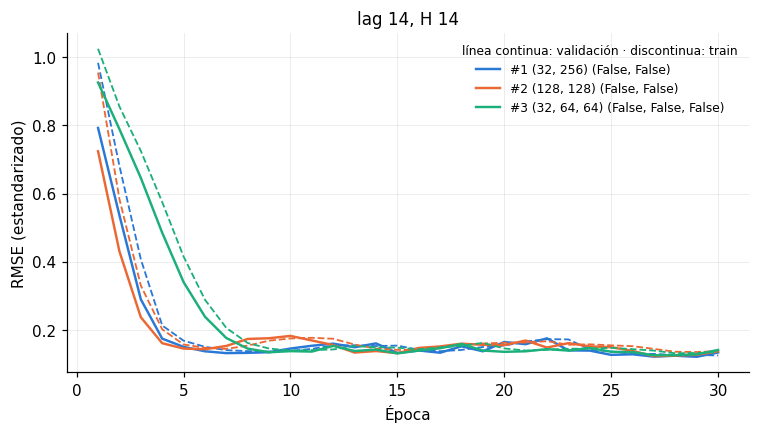

In [6]:
CURV = {(r["L"], r["H"], str(tuple(r["arch"])), str(tuple(r["mask"]))): r
        for r in REG if r["phase"] == "search"}

def curvas_top3(L, H, ax):
    for k, (_, f) in enumerate(TOP5[(TOP5.lag == L) & (TOP5.H == H)].head(3).iterrows()):
        r = CURV[(L, H, f.arquitectura, f.dropout_mask)]
        ep = np.arange(1, len(r["train_curve"]) + 1)
        ax.plot(ep, r["train_curve"], color=COL[k], ls="--", lw=1.2)
        ax.plot(ep, r["val_curve"], color=COL[k], lw=1.6, label=f"#{k+1} {f.arquitectura} {f.dropout_mask}")
    ax.set_title(f"lag {L}, H {H}"); ax.set_xlabel("Época"); ax.set_ylabel("RMSE (estandarizado)")

fig, ax = plt.subplots(figsize=(8, 4))
curvas_top3(14, 14, ax)
ax.legend(fontsize=8, title="línea continua: validación · discontinua: train", title_fontsize=8)
guardar(fig, "busqueda_top3_L14_H14"); plt.show()

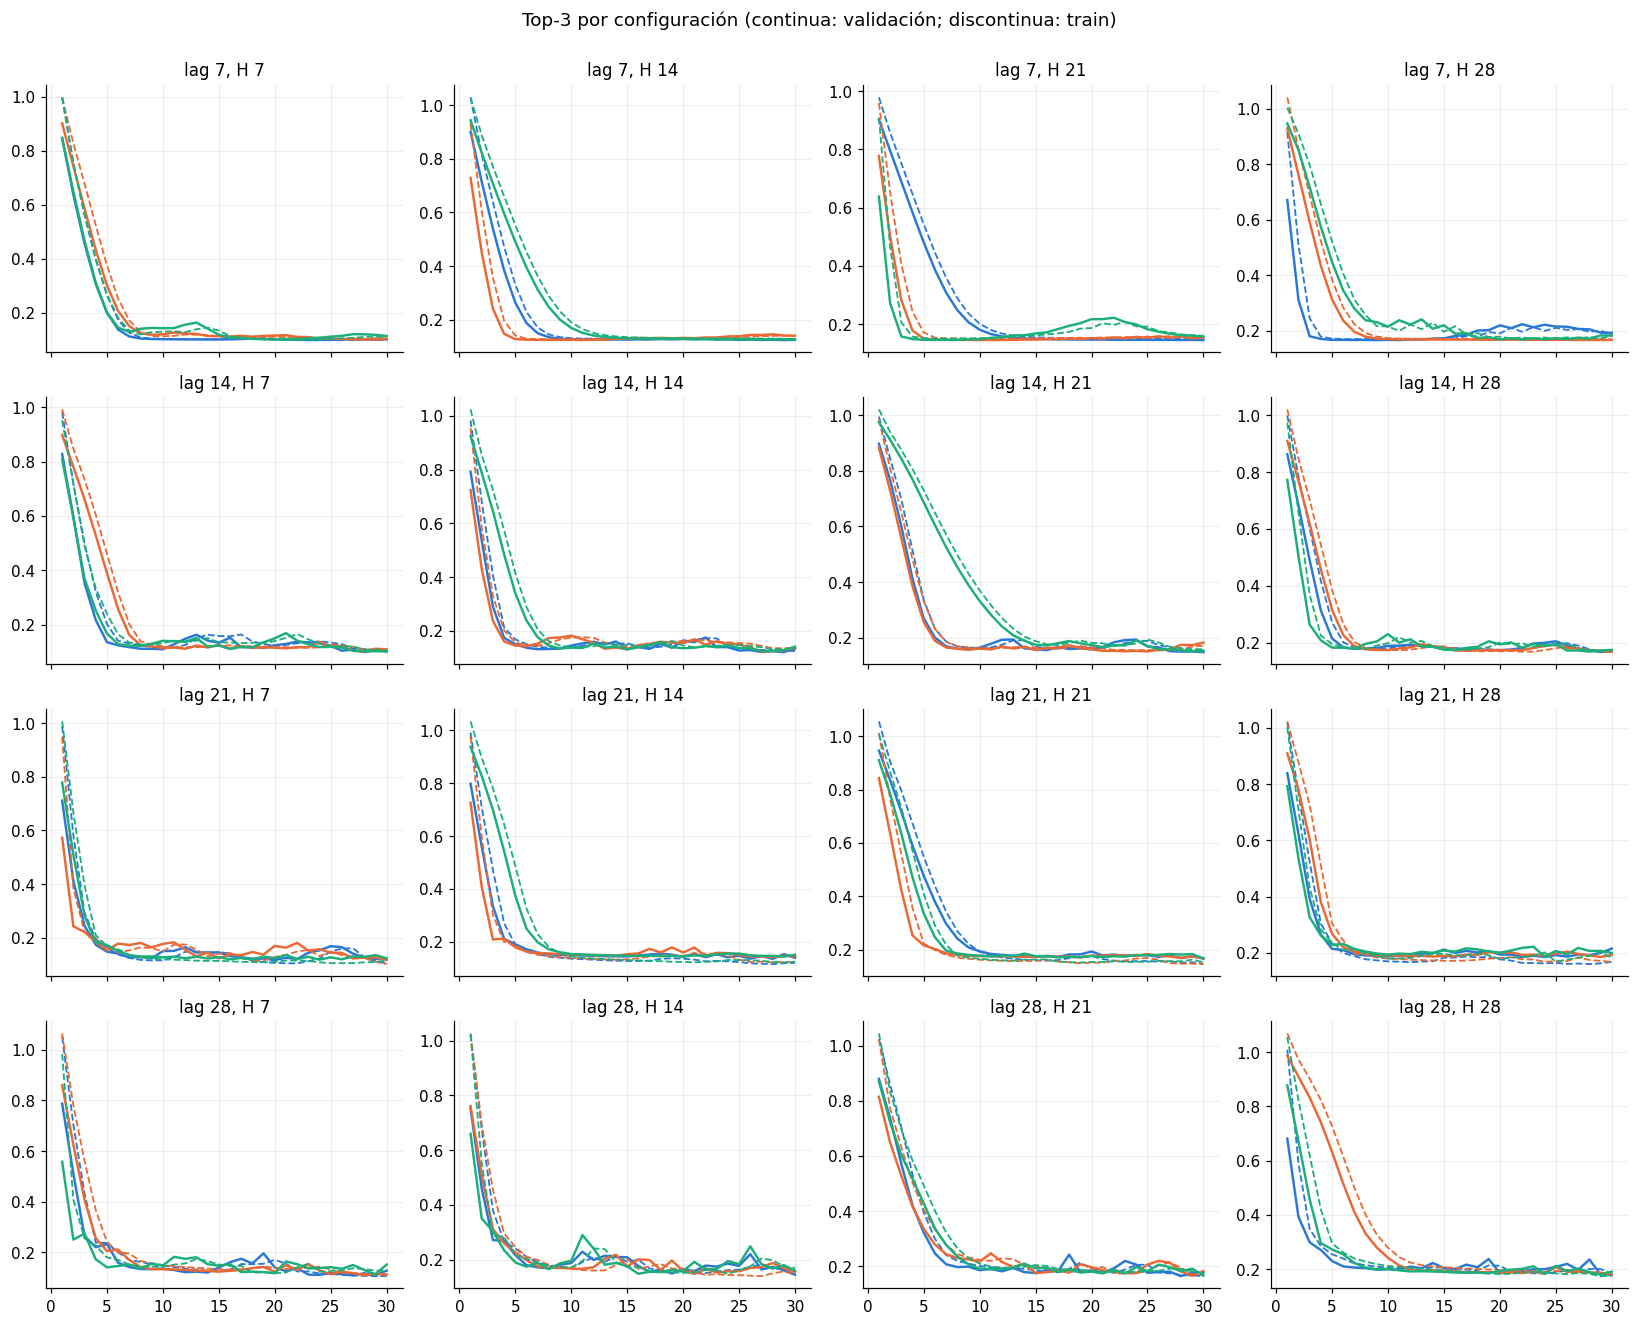

In [7]:
fig, axs = plt.subplots(4, 4, figsize=(15, 12), sharex=True)
for i, L in enumerate(LAGS):
    for j, H in enumerate(HS):
        if len(TOP5[(TOP5.lag == L) & (TOP5.H == H)]):
            curvas_top3(L, H, axs[i, j])
        axs[i, j].set_xlabel(""); axs[i, j].set_ylabel("")
fig.suptitle("Top-3 por configuración (continua: validación; discontinua: train)", y=1.0)
fig.tight_layout(); guardar(fig, "busqueda_top3_todas"); plt.show()

En las 16 configuraciones el patrón de las curvas es el mismo. El RMSE baja de forma brusca en las primeras 5 a 10 épocas y luego se estabiliza entre 0.1 y 0.2. Las curvas de entrenamiento (discontinuas) y de validación (continuas) quedan prácticamente superpuestas al final de las 30 épocas: no hay sobreajuste visible, lo que es consistente con que el filtro de `gap_ratio` se cumpla con facilidad en las arquitecturas sin dropout. Algunas curvas de validación muestran oscilaciones de época a época (por ejemplo, lag 7 con H 21 y lag 28 con H 14), propias de validar sobre bloques cortos de una serie volátil. Con 30 épocas el entrenamiento ya está en la meseta, así que más épocas no cambiarían la conclusión.

## 2.5 Efecto de profundidad, ancho y dropout


Capas ocultas
          mediana_val_rmse  mediana_gap_ratio  frac_balanceados     n
n_capas                                                             
1                  0.1687             0.4061            0.4752   101
2                  0.1741             0.6448            0.2242   785
3                  0.2016             0.5415            0.1575  6325

Neuronas por capa (media)
              mediana_val_rmse  mediana_gap_ratio  frac_balanceados    n
ancho_medio                                                            
32.000000              0.2453             0.5685            0.2099  181
42.666667              0.2460             0.5601            0.1262  317
48.000000              0.1906             0.7762            0.2632   95
53.333333              0.2249             0.6138            0.1429  301
64.000000              0.2134             0.5854            0.1879  479
74.666667              0.2079             0.5592            0.1707  580
80.000000              0.1797      

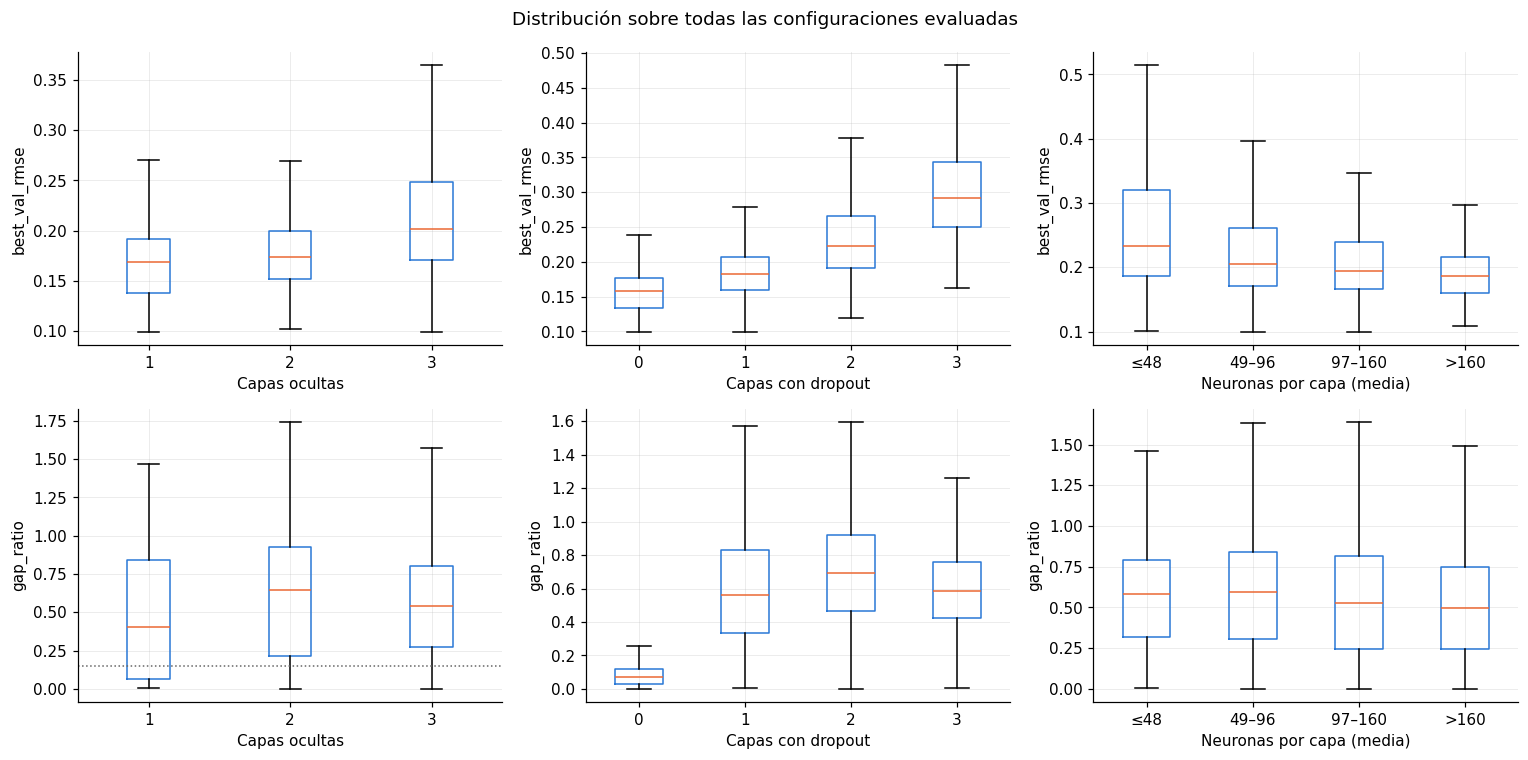

In [8]:
efectos = {}
for var, nombre in (("n_capas", "Capas ocultas"), ("ancho_medio", "Neuronas por capa (media)"),
                    ("n_dropout", "Capas con dropout")):
    efectos[var] = S.groupby(var).agg(mediana_val_rmse=("best_val_rmse", "median"),
                                      mediana_gap_ratio=("gap_ratio", "median"),
                                      frac_balanceados=("gap_ratio", lambda s: float((s < 0.15).mean())),
                                      n=("best_val_rmse", "size"))
    print(f"\n{nombre}\n", efectos[var].round(4).to_string())

fig, axs = plt.subplots(2, 3, figsize=(14, 7))
for j, var in enumerate(("n_capas", "n_dropout", "ancho_medio")):
    cats = sorted(S[var].unique()) if var != "ancho_medio" else None
    if var == "ancho_medio":
        S["_ancho"] = pd.cut(S.ancho_medio, [0, 48, 96, 160, 256], labels=["≤48", "49–96", "97–160", ">160"])
        cats, v = list(S["_ancho"].cat.categories), "_ancho"
    else:
        v = var
    for i, met in enumerate(("best_val_rmse", "gap_ratio")):
        datos = [S.loc[S[v] == c, met].dropna() for c in cats]
        axs[i, j].boxplot(datos, showfliers=False, medianprops=dict(color=COL[1]), boxprops=dict(color=COL[0]))
        axs[i, j].set_xticks(range(1, len(cats) + 1)); axs[i, j].set_xticklabels([str(c) for c in cats])
        axs[i, j].set_xlabel({"n_capas": "Capas ocultas", "n_dropout": "Capas con dropout",
                              "ancho_medio": "Neuronas por capa (media)"}[var])
        axs[i, j].set_ylabel(met)
axs[1, 0].axhline(0.15, color="0.4", ls=":", lw=1)
fig.suptitle("Distribución sobre todas las configuraciones evaluadas"); fig.tight_layout()
guardar(fig, "busqueda_efectos"); plt.show()

El dropout es el factor con mayor efecto. La mediana del RMSE de validación sube de 0.159 sin dropout a 0.183, 0.223 y 0.292 con una, dos y tres capas con dropout, y la fracción de candidatas que cumple el filtro de balance cae de 82 % a 7.5 %, 4.8 % y 3.5 %. Con una tasa de 0.5, el dropout introduce una diferencia sistemática entre el error de entrenamiento (calculado con neuronas apagadas) y el de validación, y además resta capacidad a una red que no sobreajusta. En este problema no hay sobreajuste que corregir, por eso el dropout solo empeora.

La profundidad tiene un efecto menor: la mediana pasa de 0.169 (una capa) a 0.174 (dos) y 0.202 (tres), con más dispersión en las de tres capas. Las redes más anchas tienen medianas algo menores (de cerca de 0.23 con 48 neuronas o menos por capa a 0.19 con más de 160). Estas medianas mezclan grupos de tamaño muy distinto: el 88 % de las candidatas (6325 de 7211) tiene tres capas, porque el número de máscaras crece como 2 elevado al número de capas. La comparación por profundidad está, por tanto, confundida con la proporción de candidatas con dropout en cada grupo.

## 2.6 ¿Cambia la arquitectura óptima con el horizonte?

In [9]:
pd.pivot_table(MEJOR.assign(sel=MEJOR.arquitectura + " " + MEJOR.dropout_mask),
               index="lag", columns="H", values="sel", aggfunc="first")

H,7,14,21,28
lag,,,,
7,"(64,) (False,)","(64,) (False,)","(32,) (False,)","(256,) (False,)"
14,"(32, 64, 128) (False, False, False)","(32, 256) (False, False)","(32, 32, 128) (False, False, False)","(64, 128) (False, False)"
21,"(64, 128, 128) (False, False, False)","(32, 256) (False, False)","(32, 128, 64) (False, False, False)","(32, 128, 256) (False, False, False)"
28,"(32, 128, 256) (False, False, False)","(128, 128, 256) (False, False, False)","(128, 64, 128) (False, False, False)","(256, 256) (False, False)"


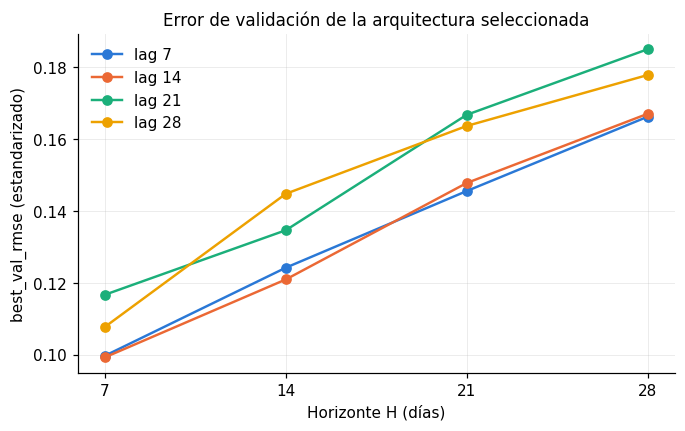

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for L in LAGS:
    g = MEJOR[MEJOR.lag == L].sort_values("H")
    ax.plot(g.H, g.best_val_rmse, marker="o", ms=6, color=COL_LAG[L], label=f"lag {L}")
ax.set_xticks(HS); ax.set_xlabel("Horizonte H (días)"); ax.set_ylabel("best_val_rmse (estandarizado)")
ax.set_title("Error de validación de la arquitectura seleccionada"); ax.legend()
guardar(fig, "busqueda_mejor_vs_H"); plt.show()

La arquitectura ganadora cambia con el horizonte y con el lag; no hay una arquitectura única que domine. Lo que sí es estable es la ausencia de dropout y la tendencia del error: en los cuatro lags el `best_val_rmse` crece de forma casi monótona con H, desde 0.099–0.117 con H = 7 hasta 0.166–0.185 con H = 28. Los lags 7 y 14 obtienen los menores errores en los cuatro horizontes; los lags 21 y 28 quedan por encima en casi todos los casos. Más memoria de entrada no mejora el pronóstico, lo que concuerda con el EDA: la autocorrelación parcial del nivel se concentra en el rezago 1.

## 2.7 Síntesis

- La búsqueda cubrió el espacio completo en (14, 14) y una muestra aleatoria del 75.6 % en las otras 15 configuraciones.
- Ninguna de las 16 ganadoras usa dropout; con una tasa de 0.5 el dropout empeora el error y el balance en todas las profundidades.
- El error de validación crece con el horizonte en todos los lags, y los lags cortos (7 y 14) son los mejores.
- Entre las cinco mejores candidatas de cada configuración las diferencias de validación son pequeñas y su orden no se conserva en el hold-out.